# Exploratory findings — daily rides against temperature and weather

> **Fixes applied to this notebook** (nothing else changed — same charts, same styling):
> 1. File path — was `C:/Users/gutti/Downloads/...` in one cell and a bare relative
>    name in another. Now resolved once, relative to the repo, so it runs anywhere.
> 2. Temperature bins started at a hardcoded 10 °F, which silently dropped the
>    7 coldest days of 2025 from the box plot and the outlier table. Bins are now
>    derived from the data at both ends and defined **once**, so every cell bins
>    the same way.
> 3. The outlier cell crashed on pandas 3 (`KeyError: 'temp_bin'`). Rewritten
>    without `groupby.apply`.
> 4. The weather box plot compared snow/rain/dry days across the whole year, which
>    mostly measured winter against summer. Now split by season, and the wet/dry
>    threshold matches `precip_any` in `build_dataset.py`.
>
> Renamed from `cluster.ipynb`: what it contains is exploratory analysis
> (component 1 of the brief), not clustering. The unsupervised-learning component
> is still outstanding and needs its own notebook — a unit of analysis, an
> algorithm and a justified cluster count.

In [1]:
#Exploratory findings
#Bins of Weather, Rides, Histogram and Box Plots
import pandas as pd
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np

## Load

One path, resolved relative to the repo root, so this runs on any machine from a
clean clone. The notebook previously read the same file from two different
locations in two different cells.

In [2]:
# walk up from the notebook until we find the repo's data folder
here = Path.cwd()
for parent in [here, *here.parents]:
    candidate = parent / "data" / "divvy_daily_merged.csv"
    if candidate.exists():
        DATA = candidate
        break
else:
    raise FileNotFoundError("data/divvy_daily_merged.csv not found above " + str(here))

df = pd.read_csv(DATA, parse_dates=["date"])
print(f"loaded {DATA}  ->  {len(df)} days, "
      f"{df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d}, {df.rides.sum():,} rides")
df.head()

loaded /home/claude/work/clusterfix/data/divvy_daily_merged.csv  ->  365 days, 2025-01-01 to 2025-12-31, 5,552,941 rides


,date,rides,member,casual,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,rain,snowfall,...,cloud_cover,temp_max,temp_min,apparent_max,hours_observed,dow,dow_name,month,is_weekend,precip_any
0,2025-01-01,3562,2321,1241,29.675000,19.570833,68.916667,0.004,0.000,0.028,...,91.750000,33.4,26.5,25.8,24,2,Wednesday,1,False,False
1,2025-01-02,4749,3807,942,27.666667,18.633333,63.416667,0.008,0.000,0.056,...,83.250000,31.5,24.5,22.9,24,3,Thursday,1,False,False
2,2025-01-03,4200,3436,764,22.833333,12.141667,55.375000,0.000,0.000,0.000,...,25.833333,26.0,18.7,16.8,24,4,Friday,1,False,False
3,2025-01-04,3198,2479,719,17.666667,7.712500,48.666667,0.000,0.000,0.000,...,35.708333,22.8,12.3,13.0,24,5,Saturday,1,True,False
4,2025-01-05,2933,2370,563,20.533333,11.058333,57.125000,0.024,0.004,0.138,...,99.416667,27.9,15.8,18.0,24,6,Sunday,1,True,True


## Temperature bins

Defined **once** here and reused by every cell below. The previous version worked
out the bins separately in three places and two of them disagreed: the histogram
derived its lower edge from the data (`-10`) while the box plot and the outlier
table hardcoded `10`. Anything colder than 10 °F fell outside `pd.cut`, became
`NaN`, and was dropped by `dropna` — 7 days of 2025, including 21 January
(1,309 rides, the quietest day of the winter) and the 17–19 February cold snap.

In [3]:
temps = df["temperature_2m"]                      # average daily temperature (°F)
lo = int(np.floor(temps.min() / 10) * 10)
hi = int(np.floor(temps.max() / 10) * 10) + 10
BINS   = np.arange(lo, hi + 10, 10)
LABELS = [f"{b}-{b+10}" for b in BINS[:-1]]

df["temp_bin"] = pd.cut(temps, bins=BINS, labels=LABELS, right=False)

print(f"temperature range: {temps.min():.1f} to {temps.max():.1f} °F")
print(f"bins: {lo} to {hi} in 10° steps")
print(f"days falling outside the bins: {int(df['temp_bin'].isna().sum())}")
assert df["temp_bin"].isna().sum() == 0, "a day fell outside the temperature bins"

temperature range: -1.4 to 87.6 °F
bins: -10 to 90 in 10° steps
days falling outside the bins: 0


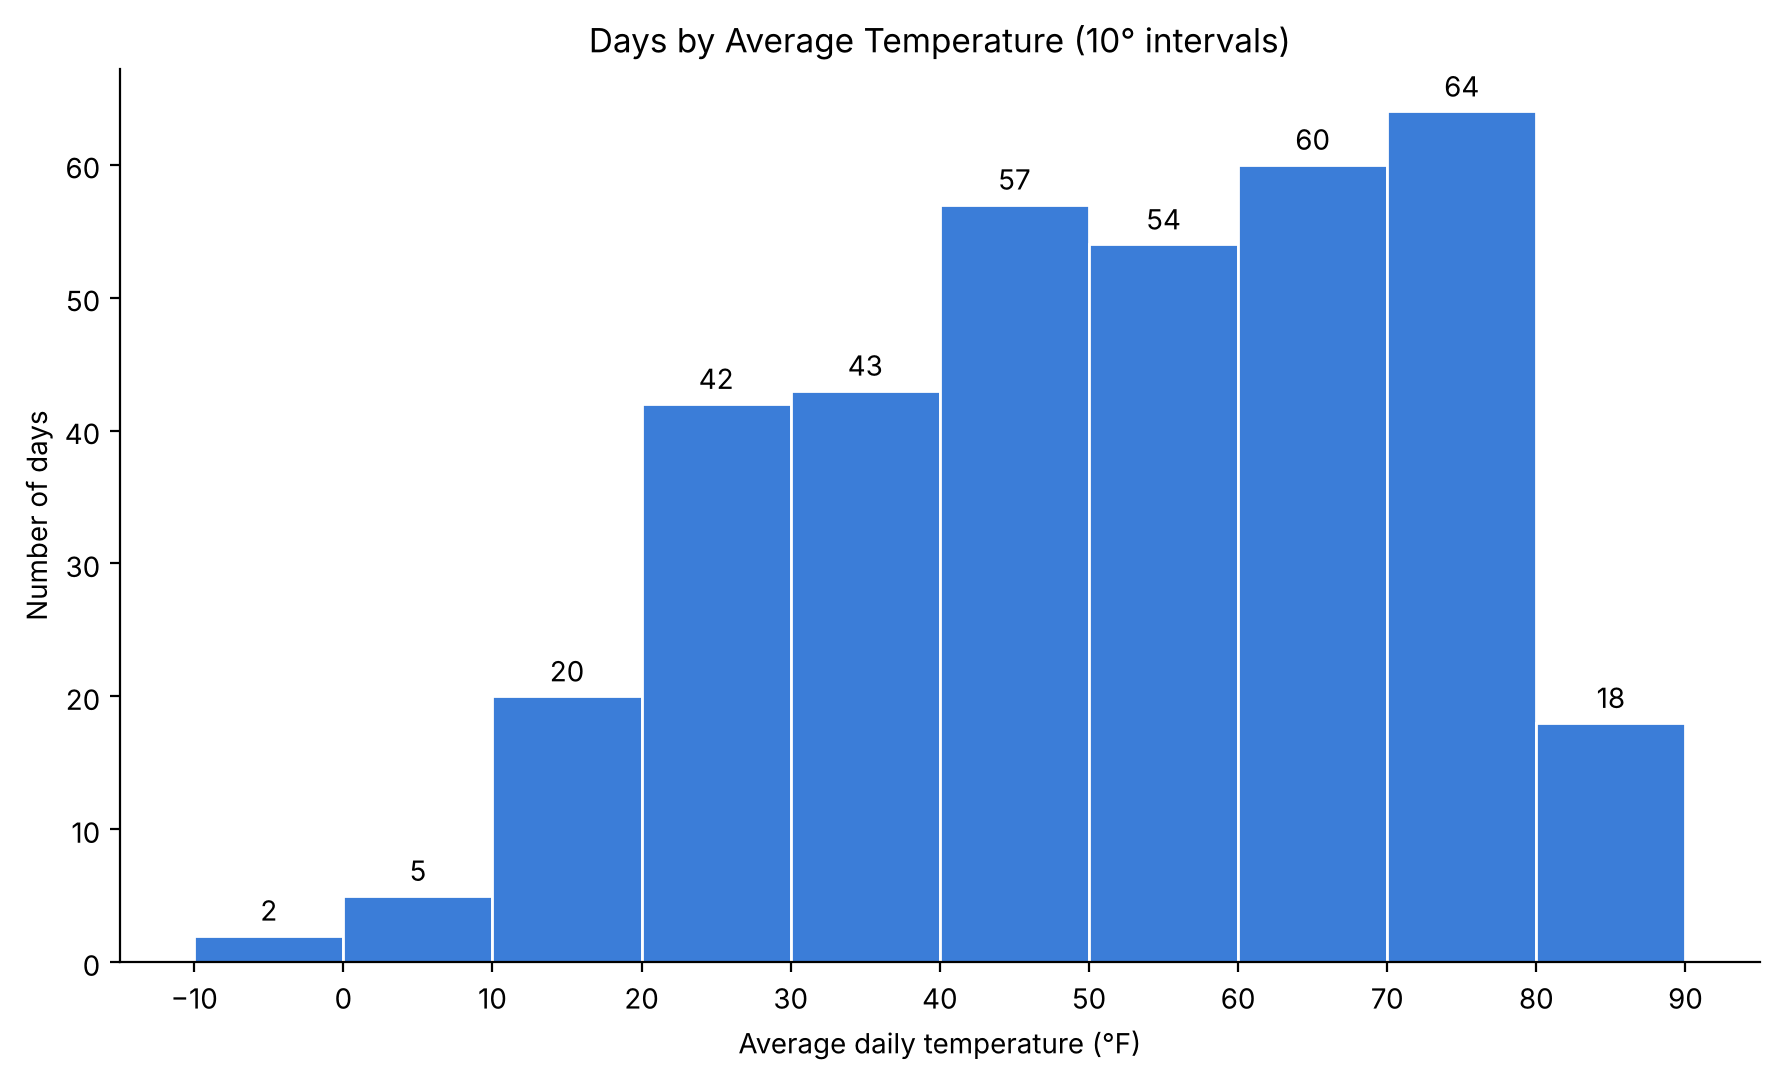

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
counts, edges, patches = ax.hist(temps, bins=BINS, color="#3b7dd8", edgecolor="white")
ax.bar_label(patches, padding=3)
ax.set_xticks(BINS)
ax.set_xlabel("Average daily temperature (°F)")
ax.set_ylabel("Number of days")
ax.set_title("Days by Average Temperature (10° intervals)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Rides by temperature

Same chart as before, now using the shared bins — so the two coldest buckets, which
the previous version dropped, are present and the box plot covers the same 365 days
as the histogram above it.

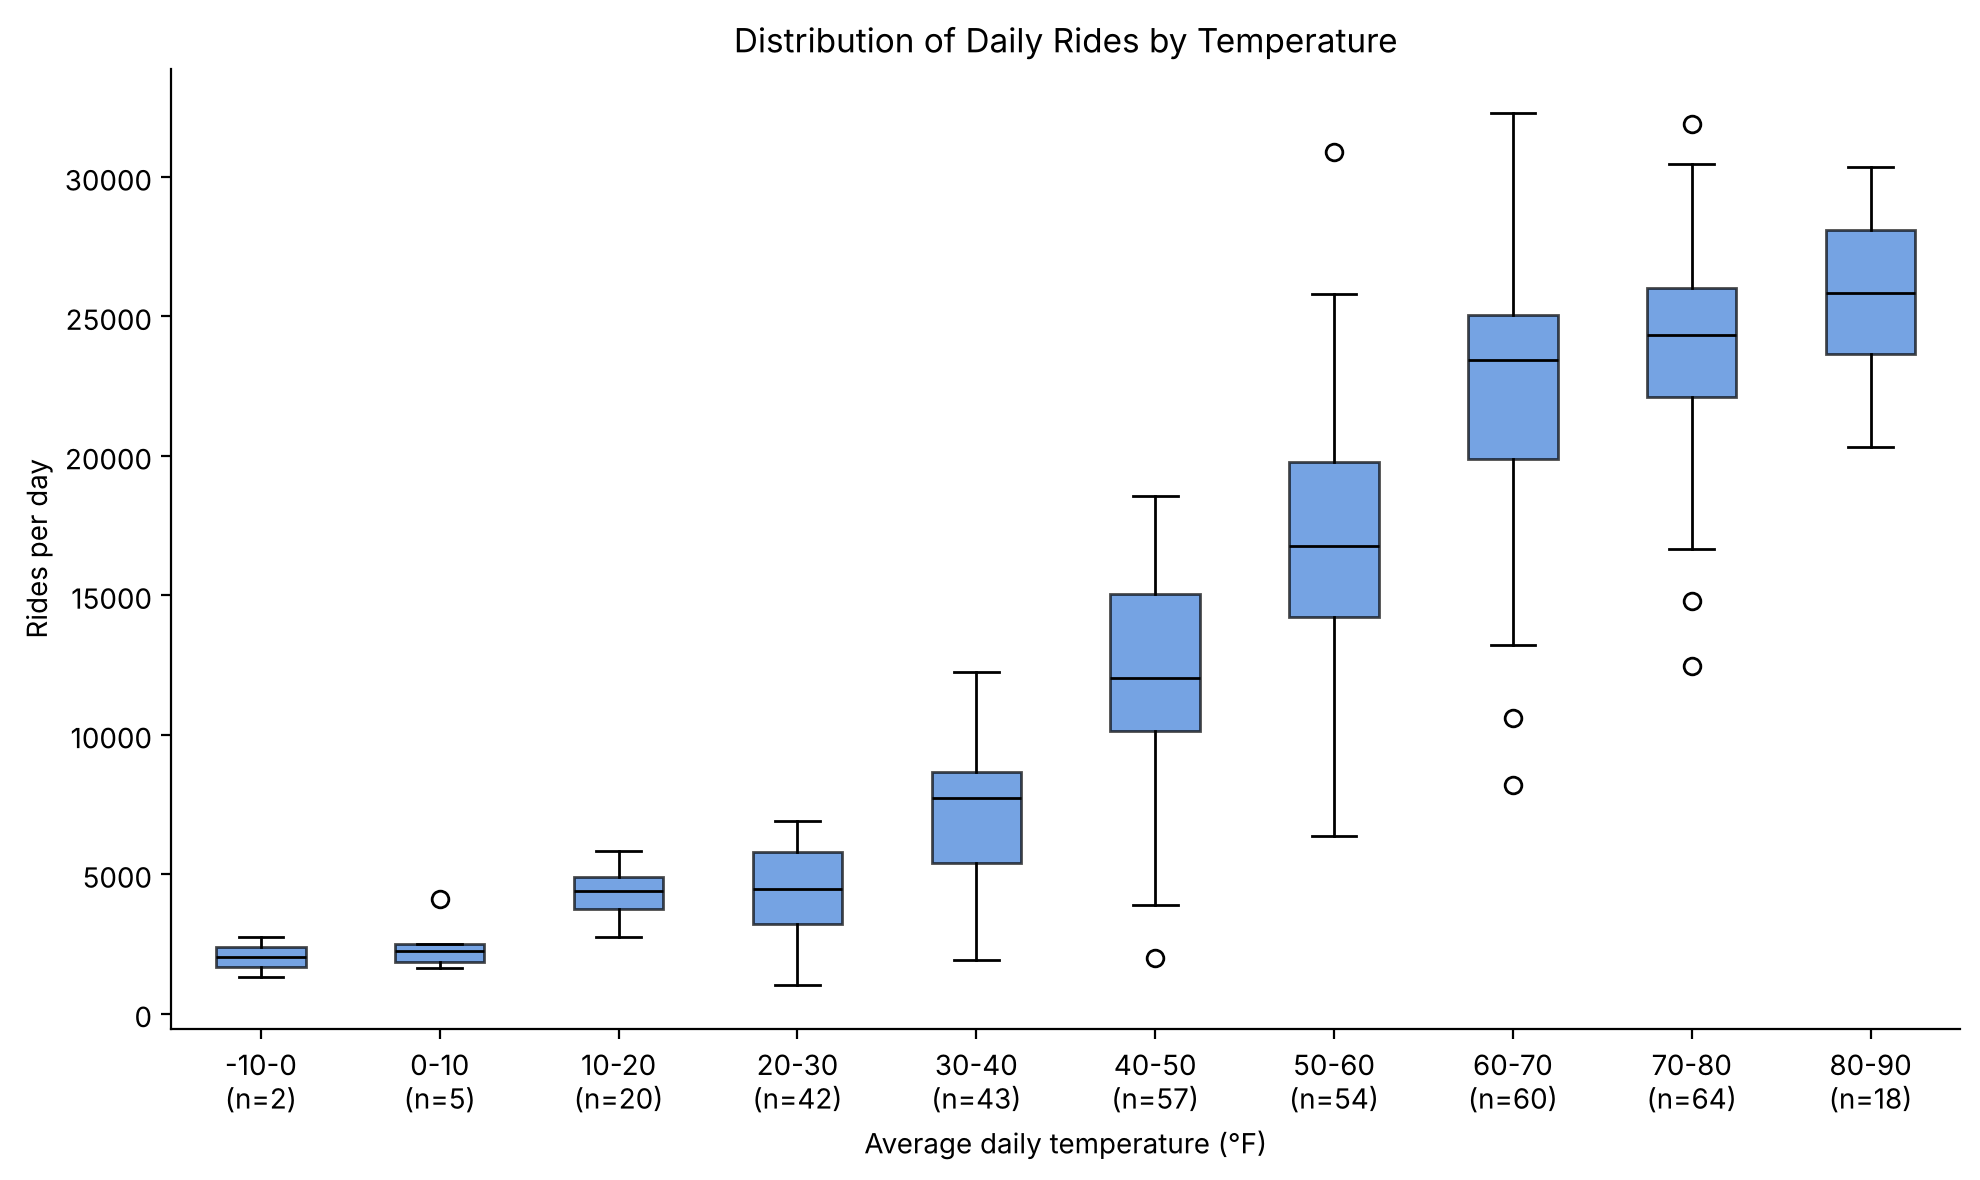

In [5]:
groups = [df.loc[df["temp_bin"] == lab, "rides"] for lab in LABELS]
tick_labels = [f"{lab}\n(n={len(g)})" for lab, g in zip(LABELS, groups)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(groups, tick_labels=tick_labels, patch_artist=True,
           boxprops=dict(facecolor="#3b7dd8", alpha=0.7),
           medianprops=dict(color="black"))
ax.set_xlabel("Average daily temperature (°F)")
ax.set_ylabel("Rides per day")
ax.set_title("Distribution of Daily Rides by Temperature")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Outliers within each temperature band

Days whose ride count sits more than 1.5 IQR outside its own temperature bucket.

The previous version used `groupby(...).apply(...)`, which stopped passing the
grouping column into the function in pandas 3, so selecting `temp_bin` back out
raised `KeyError`. `requirements.txt` allows `pandas>=2.0` with no upper bound, so
a clean `pip install -r requirements.txt` today installs 3.x and the cell fails.
Rewritten with `transform`, which behaves the same on pandas 2 and 3.

In [6]:
g   = df.groupby("temp_bin", observed=True)["rides"]
q1  = g.transform(lambda s: s.quantile(0.25))
q3  = g.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

outliers = (
    df[(df["rides"] < q1 - 1.5 * iqr) | (df["rides"] > q3 + 1.5 * iqr)]
      [["date", "temp_bin", "temperature_2m", "rides", "dow_name", "precip_any"]]
      .sort_values(["temp_bin", "date"])
      .reset_index(drop=True)
)
print(f"{len(outliers)} outlier days")
outliers

8 outlier days


,date,temp_bin,temperature_2m,rides,dow_name,precip_any
0,2025-02-19,0-10,6.883333,4113,Wednesday,False
1,2025-12-28,40-50,46.116667,1997,Sunday,True
2,2025-10-12,50-60,57.837500,30910,Sunday,False
3,2025-03-30,60-70,60.241667,8194,Sunday,True
4,2025-06-04,60-70,61.541667,10603,Wednesday,True
5,2025-06-18,70-80,71.120833,12459,Wednesday,True
6,2025-06-28,70-80,73.137500,31913,Saturday,False
7,2025-08-12,70-80,75.466667,14777,Tuesday,True


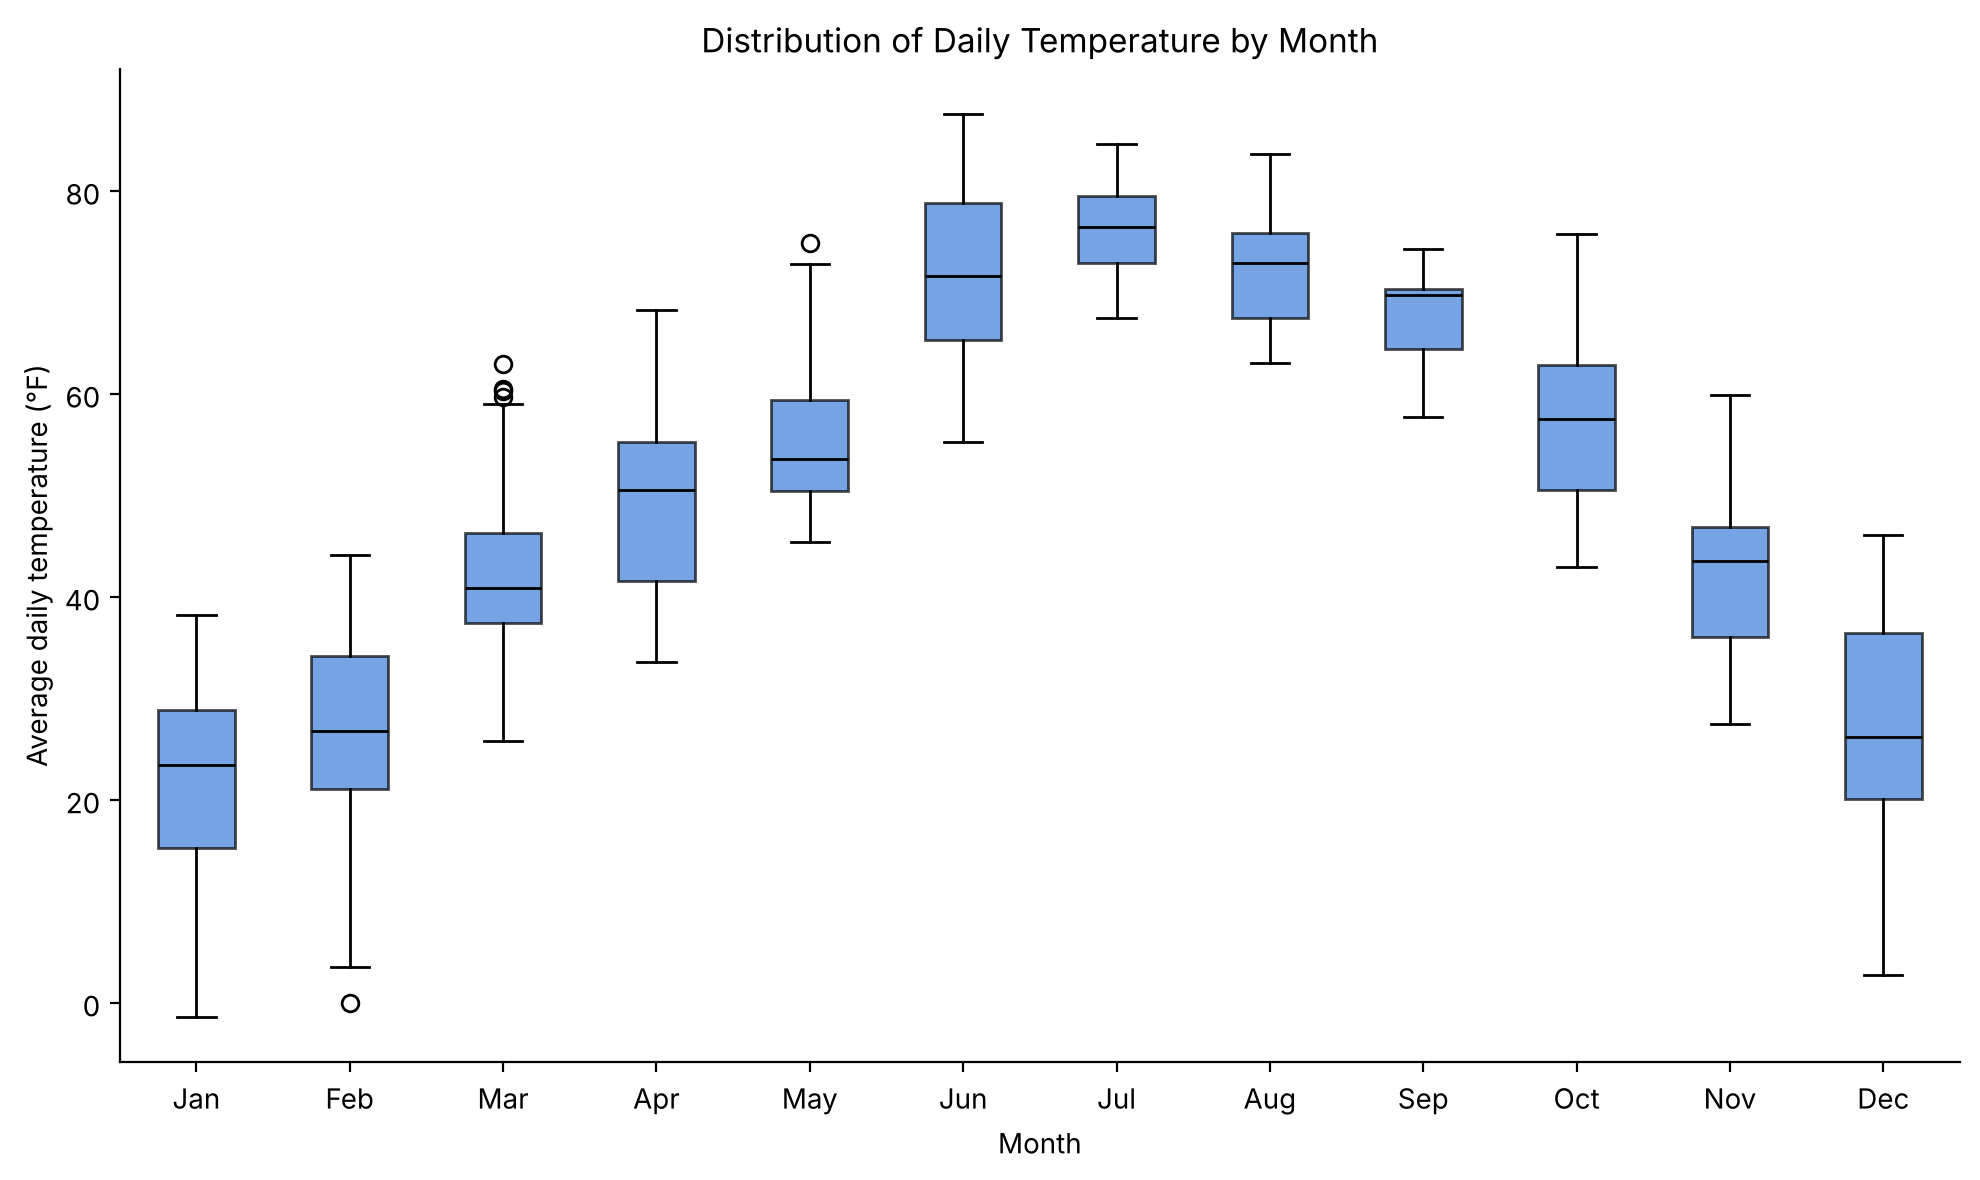

In [7]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
groups = [df.loc[df["month"] == m, "temperature_2m"] for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(groups, tick_labels=month_names, patch_artist=True,
           boxprops=dict(facecolor="#3b7dd8", alpha=0.7),
           medianprops=dict(color="black"))

ax.set_xlabel("Month")
ax.set_ylabel("Average daily temperature (°F)")
ax.set_title("Distribution of Daily Temperature by Month")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Rides by weather

Three changes here, and this is the one fix that changes what the chart *says*:

- **Split by season.** The all-year version compared 50 snow days (98% of them
  Nov–Mar) against 135 rain days (mostly Apr–Aug). Snow averaged 4,811 rides and
  rain 17,268, which looks like a weather effect but is mostly winter vs summer.
  Within a season the picture is different — see the table under the chart.
- **Threshold.** Was `> 0`, which counted 34 days with a trace of rain as wet.
  Now `> 0.01` inch, matching `precip_any` in `build_dataset.py`.
- **Snow/rain overlap.** `np.select` takes the first match, so days with both
  were labelled Snow and silently vanished from the Rain group. They are still
  labelled Snow — snow is the operationally relevant one — but the count is now
  printed rather than hidden (14 days at the corrected threshold, 23 at the old one).

14 days had both snow and rain; they are counted as Snow.


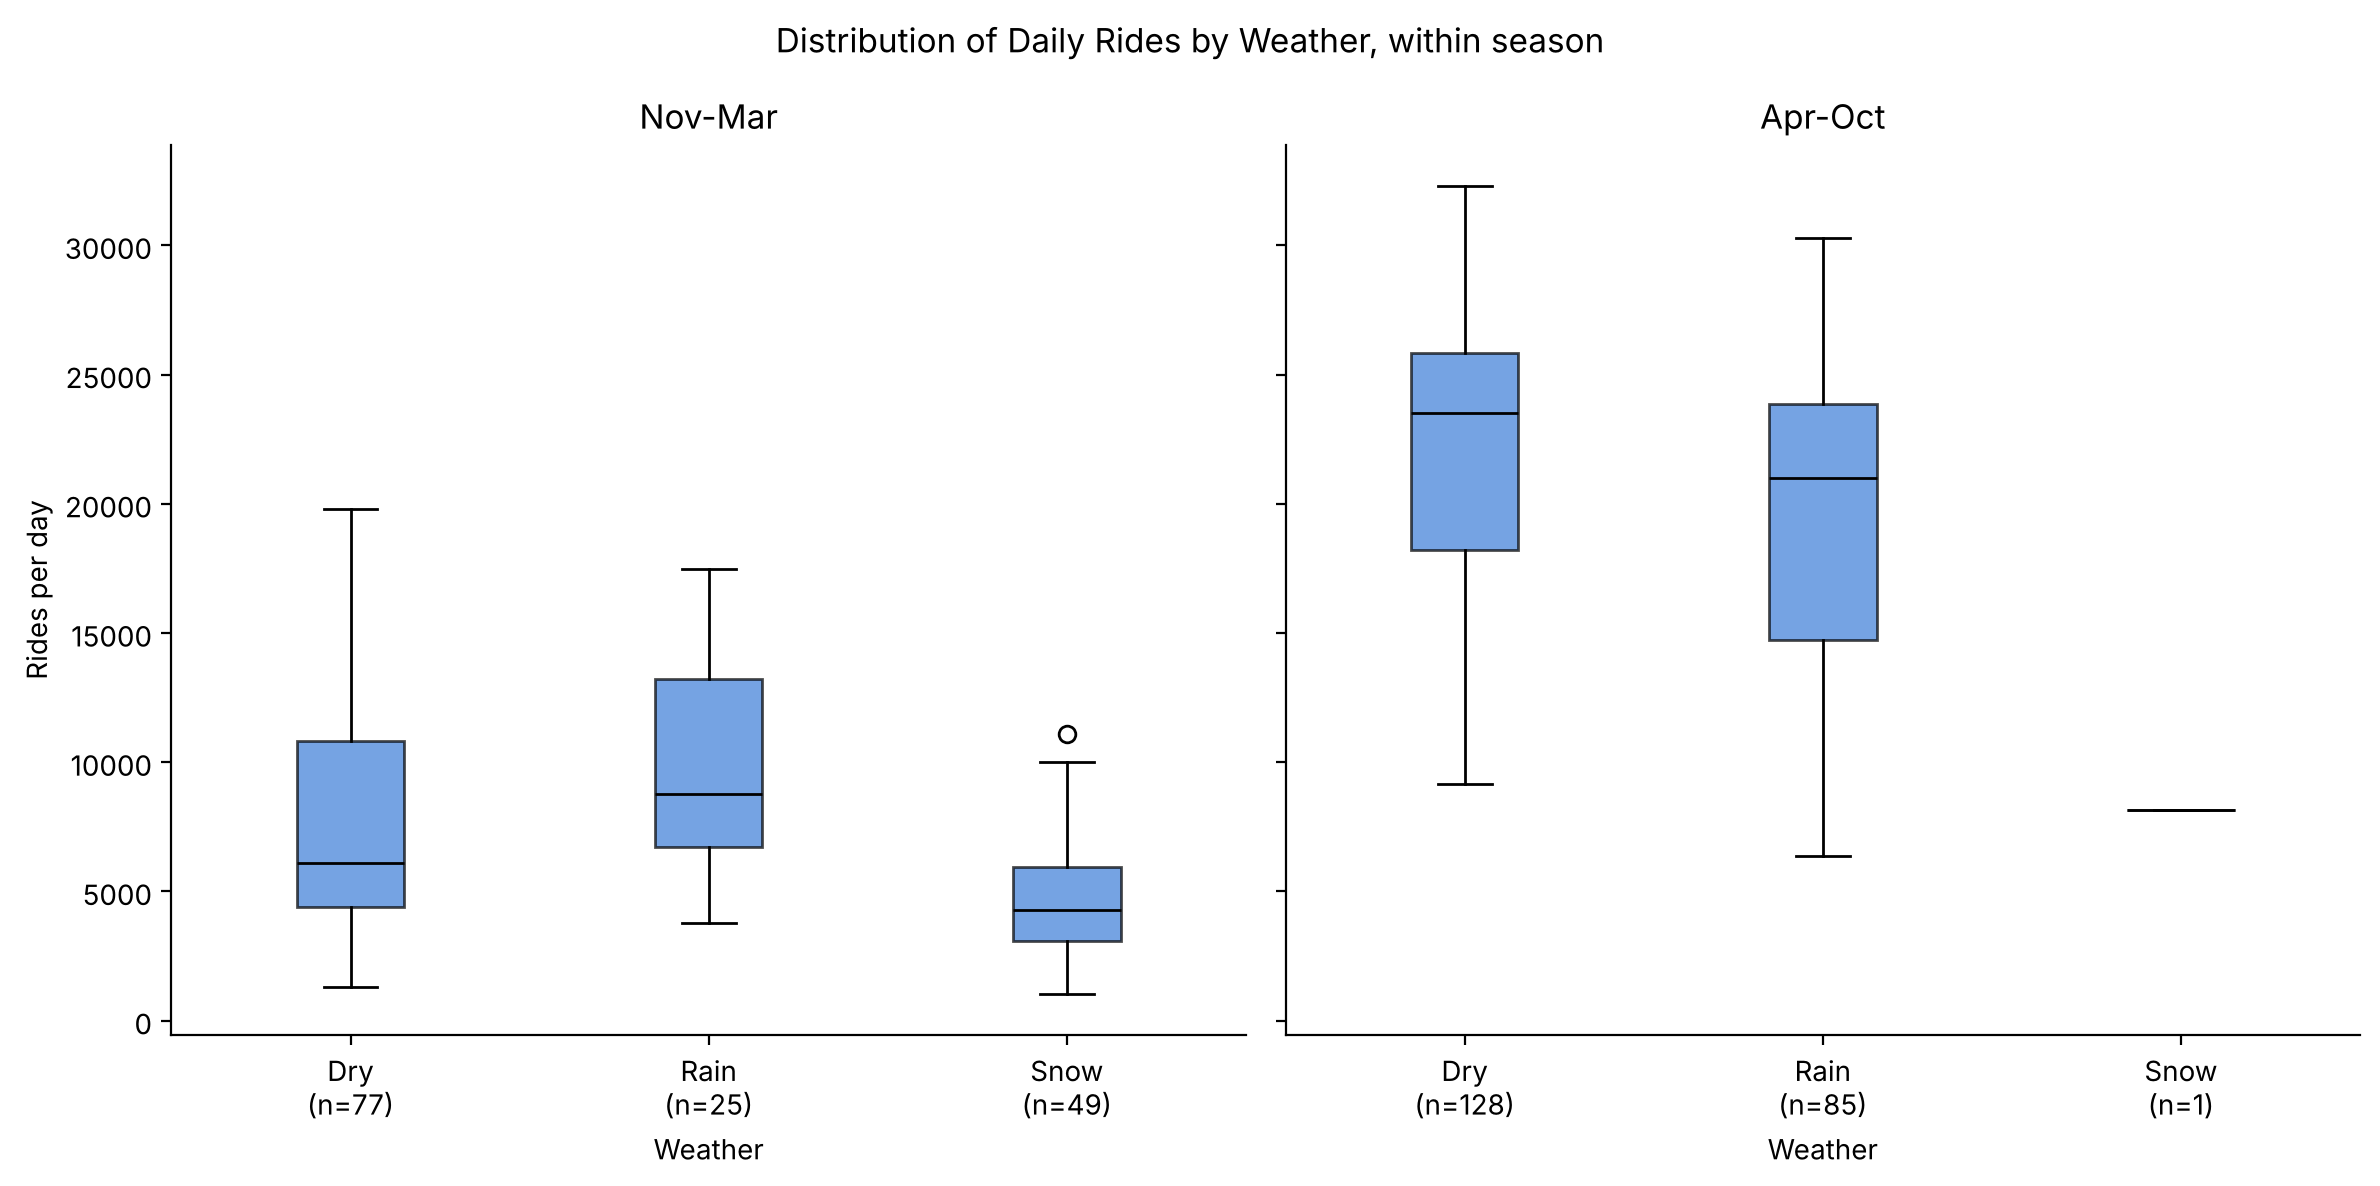


           rides         temperature_2m        
season   Apr-Oct Nov-Mar        Apr-Oct Nov-Mar
weather                                        
Dry      22056.0  7922.0           64.0    31.0
Rain     19246.0  9731.0           66.0    45.0
Snow      8147.0  4743.0           36.0    27.0


In [8]:
df["weather"] = np.select(
    [df["snowfall"] > 0.01, df["precipitation"] > 0.01],
    ["Snow", "Rain"],
    default="Dry",
)
df["season"] = np.where(df["month"].isin([11, 12, 1, 2, 3]), "Nov-Mar", "Apr-Oct")

both = int(((df["snowfall"] > 0.01) & (df["rain"] > 0.01)).sum())
print(f"{both} days had both snow and rain; they are counted as Snow.")

order = ["Dry", "Rain", "Snow"]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for ax, season in zip(axes, ["Nov-Mar", "Apr-Oct"]):
    sub = df[df["season"] == season]
    groups = [sub.loc[sub["weather"] == w, "rides"] for w in order]
    labels = [f"{w}\n(n={len(g)})" for w, g in zip(order, groups)]
    ax.boxplot(groups, tick_labels=labels, patch_artist=True,
               boxprops=dict(facecolor="#3b7dd8", alpha=0.7),
               medianprops=dict(color="black"))
    ax.set_xlabel("Weather")
    ax.set_title(season)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Rides per day")
fig.suptitle("Distribution of Daily Rides by Weather, within season")
plt.tight_layout()
plt.show()

print()
print(df.pivot_table(index="weather", columns="season", values=["rides", "temperature_2m"],
                     aggfunc="mean").round(0).to_string())

Reading the table: inside Nov–Mar, **rain days are busier than dry days** — because
a rainy January day is a warm January day (about 45 °F against 30 °F). The
all-year chart hid that completely. Snow is the real suppressor in both readings.

This is the same season-confounding trap the EDA doc already flagged for wind and
cloud cover, which is why it measured precipitation within month rather than
across the year.